In [1]:
import pandas as pd
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
df = pd.read_csv(ROOT / "data/raw/heart_raw.csv")

print(df.shape)
df.head()

(303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


## Data Dictionary
| Column | Meaning | Values |
|---|---|---|
| age | Age in years | numeric |
| sex | Sex | 1 = male, 0 = female |
| cp | Chest pain type | 1 typical angina, 2 atypical, 3 non-anginal, 4 asymptomatic |
| trestbps | Resting blood pressure (mm Hg) | numeric |
| chol | Serum cholesterol (mg/dl) | numeric |
| fbs | Fasting blood sugar > 120 mg/dl | 1 = true, 0 = false |
| restecg | Resting ECG result | 0 normal, 1 ST-T abnormality, 2 LV hypertrophy |
| thalach | Max heart rate achieved | numeric |
| exang | Exercise-induced angina | 1 = yes, 0 = no |
| oldpeak | ST depression induced by exercise | numeric |
| slope | Slope of peak exercise ST segment | 1 up, 2 flat, 3 down |
| ca | No. of major vessels coloured by fluoroscopy | 0–3 |
| thal | Thalassemia test | 3 normal, 6 fixed defect, 7 reversible defect |
| num | Diagnosis | 0 = no disease, 1–4 = disease severity |

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="Set2")

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

NUMERIC = ["age", "trestbps", "chol", "thalach", "oldpeak"]
CATEGORICAL = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

In [3]:
df.info()
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


In [4]:
missing = df.isna().sum()
print("Missing values:\n", missing[missing > 0])
print("\nDuplicate rows:", df.duplicated().sum())
df[df.isna().any(axis=1)]

Missing values:
 ca      4
thal    2
dtype: int64

Duplicate rows: 0


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
87,53,0,3,128,216,0,2,115,0,0.0,1,0.0,NaN,0
166,52,1,3,138,223,0,0,169,0,0.0,1,NaN,3.0,0
192,43,1,4,132,247,1,2,143,1,0.1,2,NaN,7.0,1
266,52,1,4,128,204,1,0,156,1,1.0,2,0.0,NaN,2
287,58,1,2,125,220,0,0,144,0,0.4,2,NaN,7.0,0
302,38,1,3,138,175,0,0,173,0,0.0,1,NaN,3.0,0


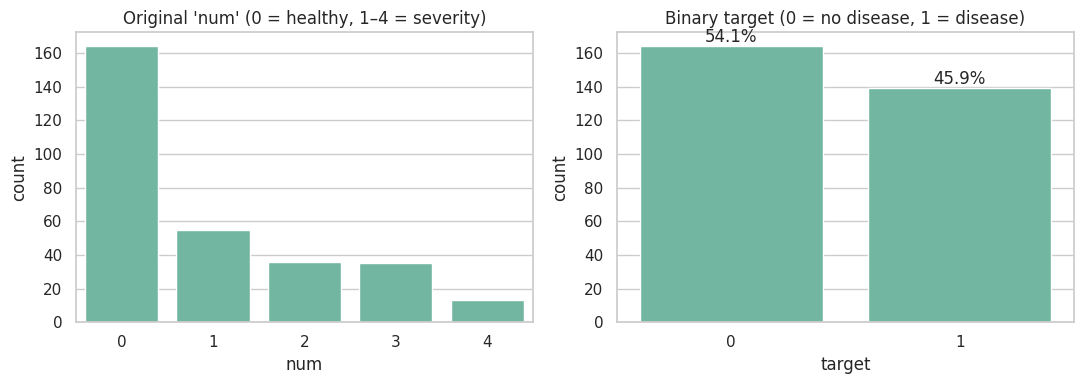

target
0    164
1    139
Name: count, dtype: int64


In [6]:
#Target and class balance
df["target"] = (df["num"] > 0).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x="num", data=df, ax=axes[0])
axes[0].set_title("Original 'num' (0 = healthy, 1–4 = severity)")

sns.countplot(x="target", data=df, ax=axes[1])
axes[1].set_title("Binary target (0 = no disease, 1 = disease)")
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height() / len(df):.1%}",
                     (p.get_x() + p.get_width() / 2, p.get_height()),
                     ha="center", va="bottom")

save_fig("01_class_balance")
plt.show()
print(df["target"].value_counts())

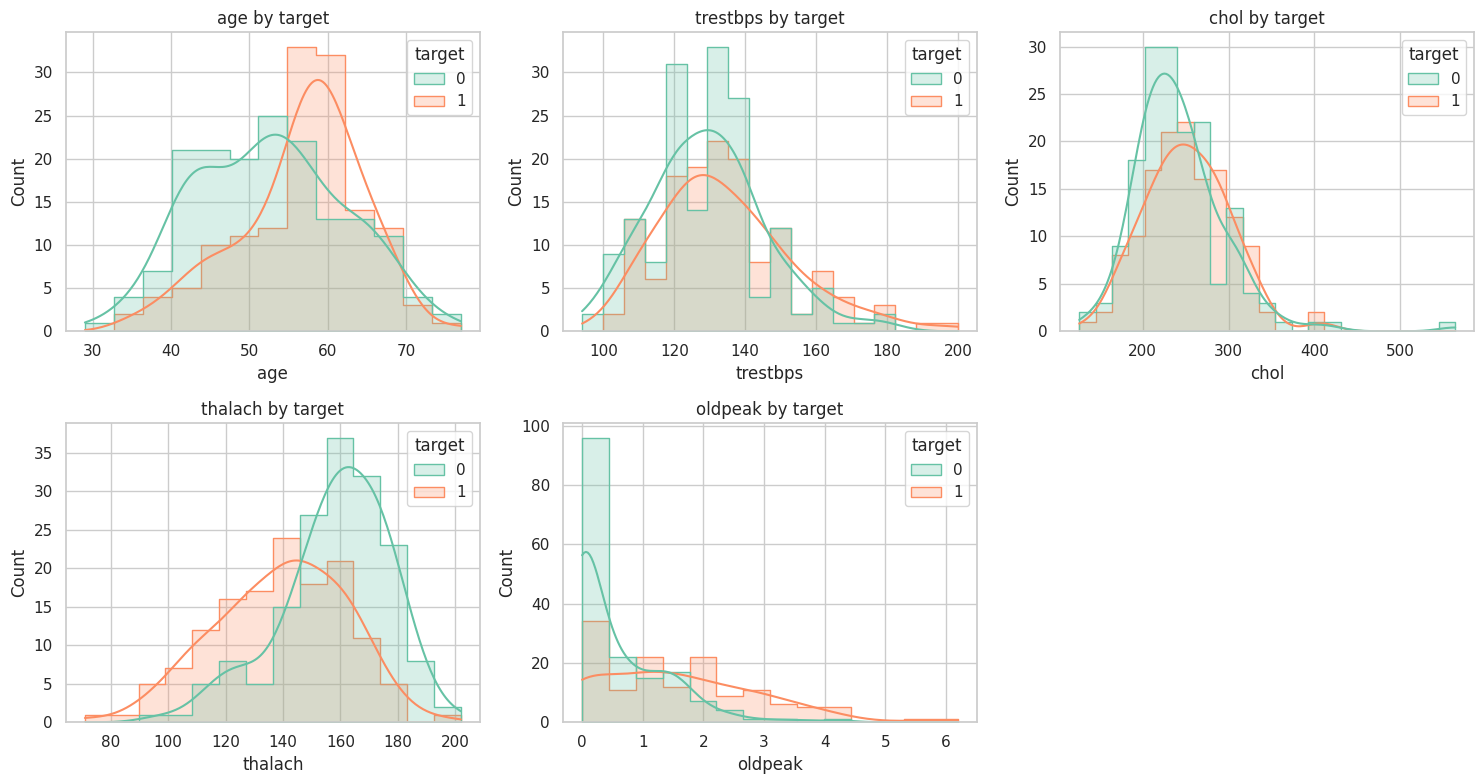

In [7]:
#Numeric feature distributions (histograms)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()
for ax, col in zip(axes, NUMERIC):
    sns.histplot(data=df, x=col, hue="target", kde=True, element="step", ax=ax)
    ax.set_title(f"{col} by target")
axes[-1].axis("off")

save_fig("02_numeric_distributions")
plt.show()

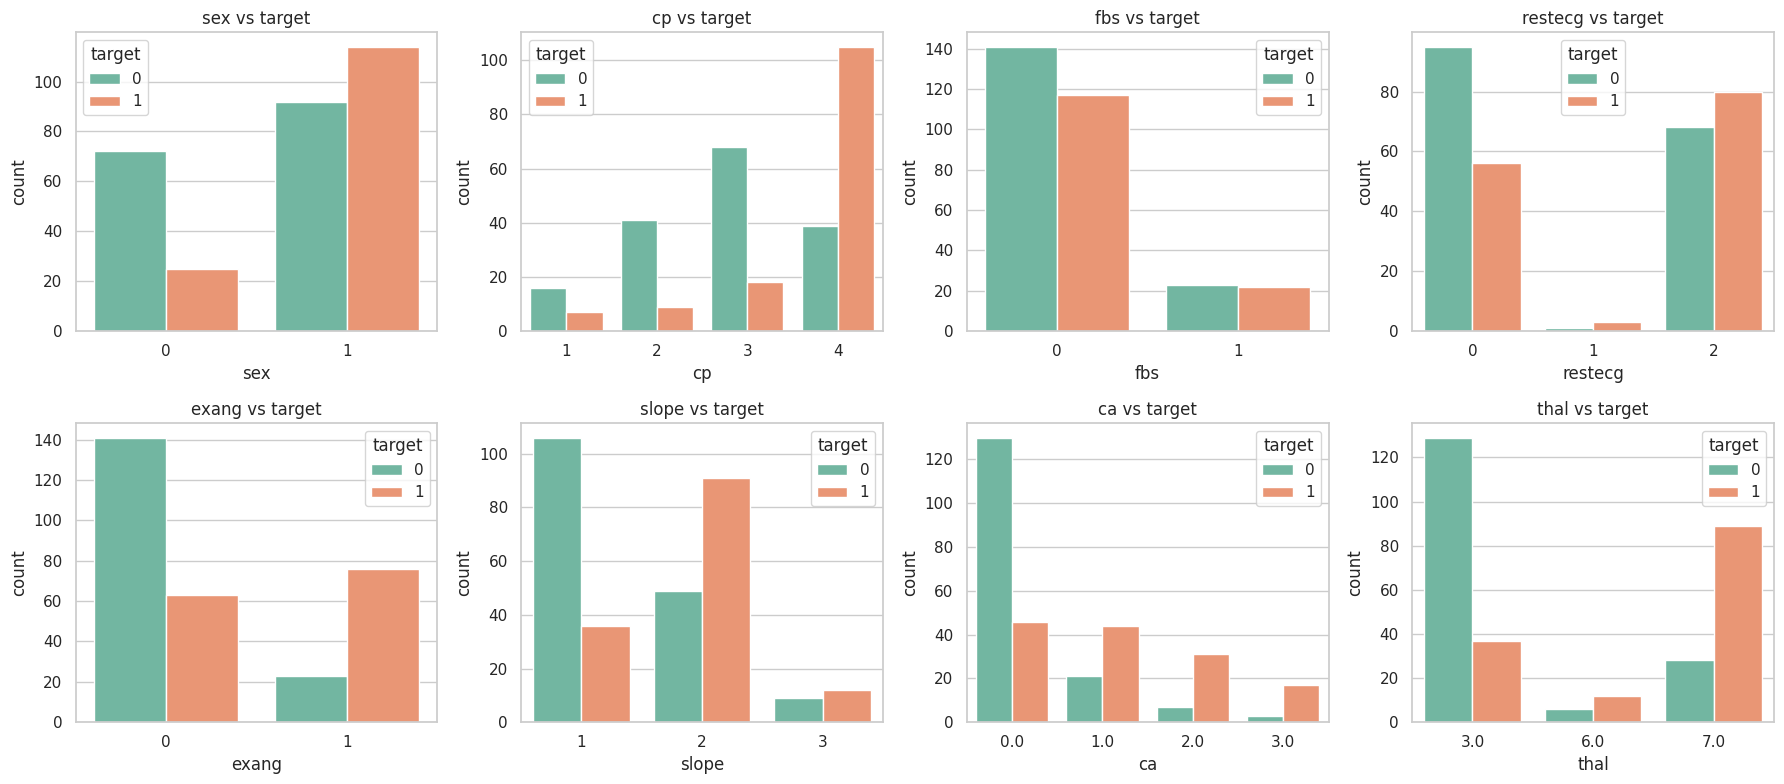

In [8]:
#Categorical features vs target
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.ravel()
for ax, col in zip(axes, CATEGORICAL):
    sns.countplot(data=df, x=col, hue="target", ax=ax)
    ax.set_title(f"{col} vs target")

save_fig("03_categorical_vs_target")
plt.show()

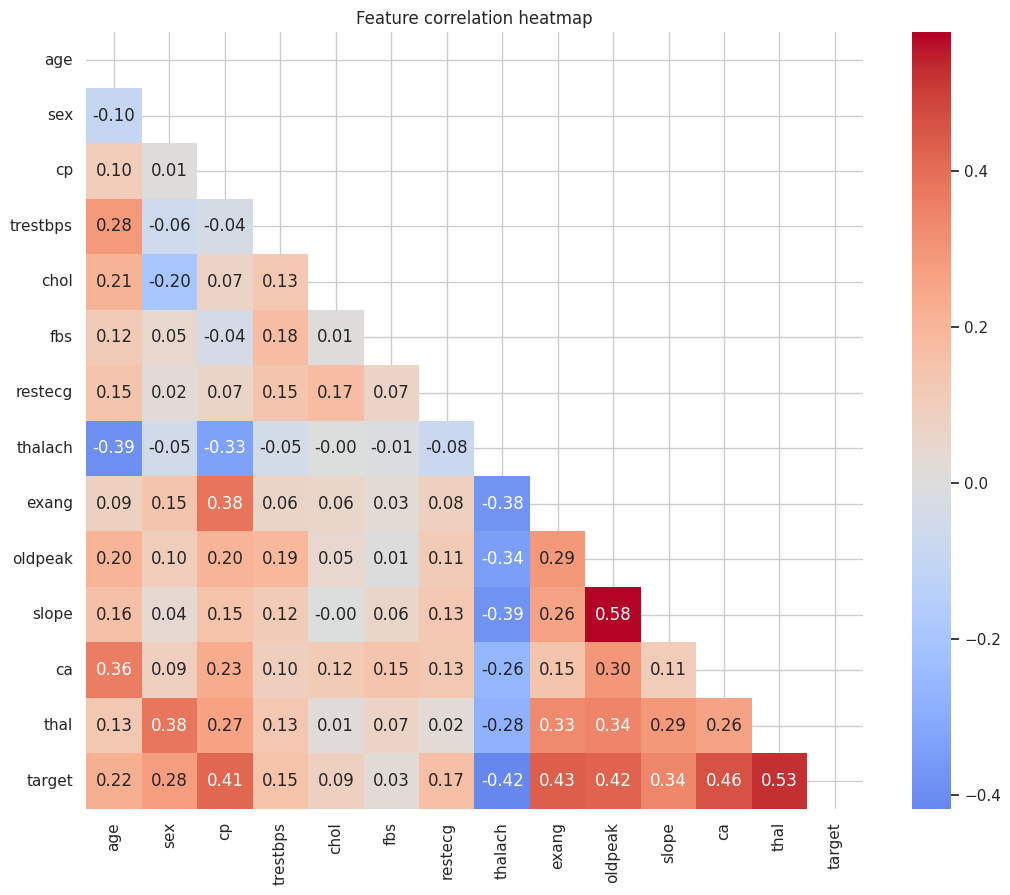

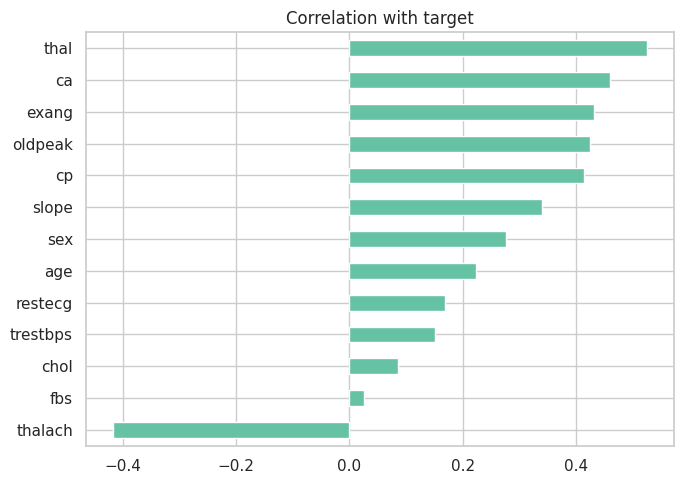

In [9]:
#Correlation heatmap
corr = df.drop(columns=["num"]).corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(11, 9))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Feature correlation heatmap")
save_fig("04_correlation_heatmap")
plt.show()

corr["target"].drop("target").sort_values().plot(kind="barh", figsize=(7, 5),
                                                 title="Correlation with target")
save_fig("05_target_correlation")
plt.show()

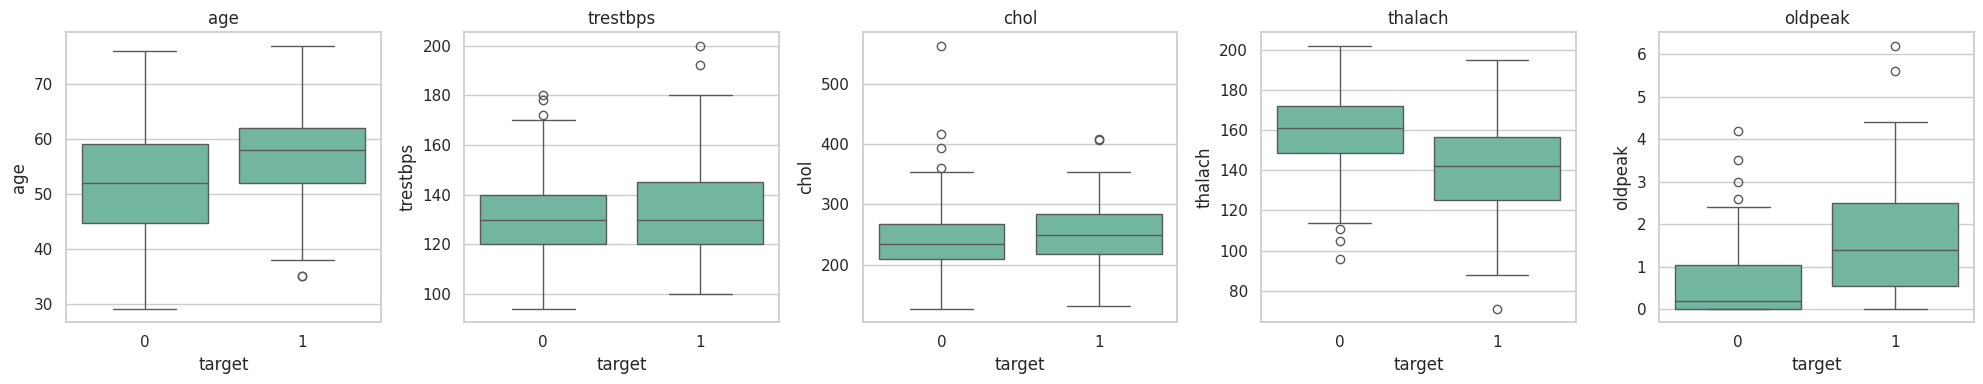

In [10]:
#Outliers
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, col in zip(axes, NUMERIC):
    sns.boxplot(data=df, x="target", y=col, ax=ax)
    ax.set_title(col)

save_fig("06_outliers_boxplots")
plt.show()

## EDA Observations

### 1. Data quality
- 303 patients, 13 features + 1 target. No duplicate rows.
- All columns are numeric, but several are actually **categorical codes** (cp, restecg, slope, thal) — they must be encoded, not treated as continuous numbers.
- **Missing values:** only 6 rows (~2%) — `ca` (4) and `thal` (2). They were stored as `?` in the raw file, which is why both columns load as float.
- Missing rows are spread across both classes (4 healthy, 2 diseased), so they are not concentrated in one group.
- **Decision:** impute with the **most frequent value (mode)** instead of dropping rows. Reason: both columns are categorical, the dataset is small (dropping loses data), and doing the imputation **inside the sklearn pipeline** avoids data leakage and lets the deployed API handle a missing value safely.

### 2. Target variable & class balance
- Original `num` ranges 0–4 (0 = no disease, 1–4 = increasing severity): 164 / 55 / 36 / 35 / 13.
- Converted to binary as required: **0 = no disease (164, 54.1%)**, **1 = disease (139, 45.9%)**.
- Only a mild imbalance → no resampling (SMOTE etc.) needed. I will use **stratified** cross-validation and report **precision, recall and ROC-AUC**, not just accuracy.
- In a medical context **recall** (catching sick patients) matters most, since a false negative is more costly than a false positive.

### 3. Numeric features
- **thalach (max heart rate):** clearly lower in diseased patients (median ≈142 vs ≈161); correlation −0.42 — one of the strongest predictors.
- **oldpeak (ST depression):** healthy patients cluster at 0, diseased patients spread to higher values (median ≈1.4 vs ≈0.2). Right-skewed.
- **age:** diseased patients are older on average (median ≈58 vs ≈52); moderate signal (0.22).
- **trestbps & chol:** heavy overlap between classes, weak signal (0.15 and 0.09).
- Features are on very different scales (oldpeak 0–6 vs chol 126–564) → **scaling is required** for Logistic Regression.

### 4. Categorical features
- **cp (chest pain):** type 4 (*asymptomatic*) is strongly linked to disease (~73% diseased), while types 2 and 3 are mostly healthy — counter-intuitive but a strong signal.
- **sex:** males show a much higher disease rate (~55%) than females (~26%).
- **exang (exercise angina):** when present, ~77% of patients have disease.
- **slope:** flat slope (2) is mostly diseased; upsloping (1) mostly healthy.
- **ca (major vessels):** a clear monotonic trend — 0 vessels is mostly healthy, 2–3 vessels almost always diseased.
- **thal:** reversible defect (7) ~76% diseased; normal (3) mostly healthy.
- **fbs:** almost no difference between classes (correlation 0.03) → weakest feature.
- **restecg = 1** occurs in only ~4 patients → rare category; the encoder must handle unseen categories safely.

### 5. Correlation analysis
- Strongest relationships with the target: **thal (0.53), ca (0.46), exang (0.43), oldpeak (0.42), thalach (−0.42), cp (0.41)**.
- Caveat: Pearson correlation on nominal codes (cp, thal) is only indicative because the code order is arbitrary — another reason to one-hot encode them.
- Highest feature-to-feature correlation is **oldpeak–slope (0.58)**; nothing above 0.6, so there is **no serious multicollinearity** and no feature needs to be dropped.

### 6. Outliers
- Extreme values exist: chol = 564, trestbps = 200, oldpeak = 6.2, thalach = 71.
- They are **clinically plausible** (not data-entry errors), so I keep them. Scaling handles their effect for Logistic Regression, and Random Forest is naturally robust to outliers.

### 7. Decisions carried into modelling
| Feature group | Columns | Treatment |
|---|---|---|
| Numeric | age, trestbps, chol, thalach, oldpeak | Median impute + StandardScaler |
| Nominal categorical | cp, restecg, slope, thal | Mode impute + One-Hot Encoding (handle_unknown="ignore") |
| Binary | sex, fbs, exang | Kept as 0/1 |
| Ordinal count | ca | Mode impute, kept numeric (0–3 order is meaningful) |
- All preprocessing goes into a single sklearn `Pipeline`, so training, testing and the API use **identical transformations** (reproducibility).
- Small dataset (303 rows) → use **5-fold stratified cross-validation** and prefer simpler, well-regularised models over very complex ones.